# Orchestrator test notebook

Two checks before the real agents exist:

**A. Pipeline on real Border 2 data.** The organizer (`graph.py` + `routing.py`) runs one cycle per real
Border 2 perimeter, with placeholder agents and no FARSITE. One observation is rejected on purpose, to check
that it's replaced by a synthetic perimeter and that the forecast and assimilation steps still run. The
weather step calls the real `adapter.fetch_weather` and caches each window, as the real weather agent will.

**B. Adapter smoke test.** Tests `adapter.py` against `load_observation`, `fetch_weather`, `sample_winds`, and a small 
`run_ensemble` (N = 4, 4 workers). This needs FARSITE and
`landscape.lcp` and takes a few minutes.

**Before running:** `pip install -e .` at the repo root (once per environment), and the
`orchestrator/__init__.py` that puts `src/` on the import path.

## 0. Setup

In [1]:
import time, warnings
from datetime import datetime, timedelta
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Polygon

import sys
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'orchestrator' / '__init__.py').is_file())
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import orchestrator                                   # puts <repo>/src on the import path
from orchestrator.state import ObservationEvent, OperatorRequest, ForecastPlan, BASELINE, initial_state
from orchestrator.graph import build_pipeline, run_pipeline, ALL_STEPS
from orchestrator.placeholders import placeholder_nodes, placeholder_agent, PlaceholderVerdict
from orchestrator.synthetic import read_perimeter
from orchestrator import steps

print('repo:', REPO, '| orchestrator from:', Path(orchestrator.__file__).parent)

import config  # from src/
try:
    from orchestrator import adapter  # needs enkf, farsite, firemap, geometry
    print('adapter imported ✓')
except Exception as e:
    adapter = None
    print(f'⚠ adapter not importable ({type(e).__name__}: {e}); Part A will use fixed weather, Part B will not run')

repo: /home/jovyan/work/digital-twin-group/wildfire-digital-twin | orchestrator from: /home/jovyan/work/digital-twin-group/wildfire-digital-twin/orchestrator
adapter imported ✓


## Settings

Everything specific to the data or this machine is here.

In [2]:
# ---- Border 2 perimeters
PERIMETERS_PATH = None  # None = first *.geojson in config.DATA_DIR/border2_inputs; or a path
TIME_COLUMN  = None  # None = auto-detect (perimeter_timestamp, datetime, date, ...)
OBS_TIMES  = None  # optional list of exact timestamps, one per row, if the file has none
ARRIVAL_LAG_MIN = 30  # each observation reaches the system this long after it was made

# ---- Part A
REJECT_ROW  = 3  # file row of the perimeter the observation agent rejects (None = reject none)
RUN_DIR  = REPO / 'runs' / 'test_notebook'

# ---- Part B (adapter smoke test)
RUN_SMOKE_TEST  = True
SMOKE_N  = 4  # ensemble members
SMOKE_WORKERS  = 4
SMOKE_RES_M  = 150  # dist_res = perim_res
SMOKE_HOURS  = 2  # forecast length; None = up to the next observation
N_VERTEX  = 20  # vertices per perimeter (adapter default)
INIT_STD_M  = 100.0  # initial ensemble spread (m) per coordinate → cov_X = INIT_STD_M² · I. Replace with the covariance your experiment notebook starts from.
SEED  = 0

## Load the Border 2 perimeters and build observation events

One `ObservationEvent` per row. `feature_id` is the row number in the file, as `adapter.load_observation`
expects, so rows keep their original numbers even after sorting by time.

In [3]:
if PERIMETERS_PATH is None:
    found = sorted((Path(config.DATA_DIR) / 'border2_inputs').glob('*.geojson'))
    if not found:
        raise FileNotFoundError(f'No *.geojson in {Path(config.DATA_DIR) / "border2_inputs"}; set PERIMETERS_PATH')
    if len(found) > 1:
        print('several GeoJSON files found, using the first (set PERIMETERS_PATH to choose):',
              [f.name for f in found])
    PERIMETERS_PATH = found[0]
PERIMETERS_PATH = Path(PERIMETERS_PATH)

perims = gpd.read_file(PERIMETERS_PATH)
print(f'{PERIMETERS_PATH.name}: {len(perims)} rows, columns {list(perims.columns)}')

if OBS_TIMES is not None:
    times = pd.to_datetime(pd.Series(OBS_TIMES))
else:
    col = TIME_COLUMN or next((c for c in ['perimeter_timestamp', 'obs_time', 'datetime', 'timestamp',
                                           'date_time', 'PolygonDateTime', 'date', 'time']
                               if c in perims.columns), None)
    if col is None:
        raise KeyError('No timestamp column found: set TIME_COLUMN or OBS_TIMES')
    raw = perims[col]
    times = (pd.to_datetime(raw, unit='ms') if pd.api.types.is_numeric_dtype(raw)
             else pd.to_datetime(raw.astype(str).str.rstrip('Z'), format='mixed'))
    print(f'time column: {col!r}')
times = times.dt.tz_localize(None) if getattr(times.dt, 'tz', None) is not None else times

events = sorted([
    ObservationEvent(obs_time=t.to_pydatetime(),
                     arrival_time=(t + pd.Timedelta(minutes=ARRIVAL_LAG_MIN)).to_pydatetime(),
                     source='mapped_perimeter', path=str(PERIMETERS_PATH), feature_id=str(i),
                     injected='shifted_2km' if i == REJECT_ROW else None)
    for i, t in enumerate(times)], key=lambda e: e.obs_time)

perims_5070 = perims.to_crs(5070)
centroid = perims.to_crs(4326).geometry.union_all().centroid
LAT, LON = centroid.y, centroid.x
display(pd.DataFrame({'row': [int(e.feature_id) for e in events], 'obs_time': [e.obs_time for e in events],
                      'area_km2': [round(perims_5070.geometry.iloc[int(e.feature_id)].area / 1e6, 2) for e in events],
                      'rejected in Part A': [e.injected is not None for e in events]}))
print(f'fire centroid: {LAT:.4f}, {LON:.4f}')

border_2_perimeters.geojson: 6 rows, columns ['year', 'fire_name', 'agency', 'acres', 'mapmethod', 'inciwebid', 'alarm_date', 'cont_date', 'comments', 'complex_name', 'perimeter_timestamp', 'cause', 'datetime', 'geometry']
time column: 'perimeter_timestamp'


,row,obs_time,area_km2,rejected in Part A
0,0,2025-01-23,2.29,False
1,1,2025-01-23,2.29,False
2,2,2025-01-23,2.29,False
3,3,2025-01-24,17.14,True
4,4,2025-01-24,25.33,False
5,5,2025-01-26,26.67,False


fire centroid: 32.6148, -116.8765


## A. Pipeline on real data (placeholder agents, no FARSITE)

- **observation:** placeholder; rejects the event marked above (`REJECT_ROW`), accepts the rest
- **weather:** fetches the real weather for each window via `adapter.fetch_weather` and caches it in
  `cache["weather_last"]` (fixed weather if the adapter isn't importable)
- **forecast / assimilation:** placeholders (no FARSITE / EnKF)
- **receive, synthesize, update:** the real steps

In [4]:
FALLBACK_WEATHER = {'wind_speeds': [10.0], 'wind_directions': [225.0], 'used_fallback': True}

def weather_step(state):
    # Placeholder decision ('use'), real data: fetch the window since the previous observation
    # and cache it like the real weather agent will.
    ev = state['current']
    good = state['cache'].get('good_obs', [])
    start = (ObservationEvent.model_validate(good[-1]).obs_time if good else ev.obs_time - timedelta(hours=6))
    if adapter is not None:
        try:
            wx = adapter.fetch_weather(start, ev.obs_time, lat=LAT, lon=LON)
        except Exception as e:
            print(f'  ⚠ fetch_weather failed ({e}); using fallback')
            wx = FALLBACK_WEATHER
    else:
        wx = FALLBACK_WEATHER
    out = placeholder_agent('weather', 'weather_verdict', 'use')(state)
    out['cache'] = {**state['cache'], 'weather_last': wx}
    return out

def reject_marked(state):
    return 'reject' if state['current'].injected else 'use'

trace = []                                            # every step name, in call order
def traced(name, fn):
    def node(state):
        trace.append(name)
        return fn(state)
    return node

nodes = placeholder_nodes(obs_action=reject_marked)
nodes['weather'] = weather_step
graph = build_pipeline({name: traced(name, fn) for name, fn in nodes.items()})

state = initial_state(events, OperatorRequest(deadline_min=30), state_path=str(RUN_DIR / 'state.npz'))
state['cache']['run_dir'] = str(RUN_DIR)
t0 = time.time()
final = run_pipeline(graph, state)
print(f'pipeline finished in {time.time() - t0:.1f} s: {len(final["metrics"])} cycles, '
      f'{len(final["log"])} log records, pending left: {len(final["pending"])}')

pipeline finished in 5.4 s: 6 cycles, 19 log records, pending left: 0


### Step trace (one row per cycle)

In [5]:
rows, cur = [], []                                    # split the trace into cycles at each 'receive'
for name in trace:
    if name == 'receive' and cur:
        rows.append(cur); cur = []
    cur.append(name)
rows.append(cur)
display(pd.DataFrame({'cycle': range(1, len(rows) + 1),
                      'obs_time': [m['obs_time'] for m in final['metrics']],
                      'steps': [' → '.join(r) for r in rows]}))

expected_clean = ['receive', 'observation', 'weather', 'forecast', 'assimilation', 'update']
expected_reject = ['receive', 'observation', 'synthesize', 'weather', 'forecast', 'assimilation', 'update']
checks = []
for r, m in zip(rows, final['metrics']):
    want = expected_reject if m['obs_action'] == 'reject' and m['synthetic'] else expected_clean
    if m['obs_action'] == 'reject' and not m['synthetic']:
        want = ['receive', 'observation', 'synthesize', 'update']     # nothing to grow yet
    checks.append(r == want)
print('step order as expected in every cycle:', all(checks))
assert all(checks), 'unexpected step order: see the table above'
assert final['pending'] == [], 'events left unprocessed'

,cycle,obs_time,steps
0,1,2025-01-23T00:00:00,receive → observation → weather → forecast → a...
1,2,2025-01-23T00:00:00,receive → observation → weather → forecast → a...
2,3,2025-01-23T00:00:00,receive → observation → weather → forecast → a...
3,4,2025-01-24T00:00:00,receive → observation → synthesize → weather →...
4,5,2025-01-24T00:00:00,receive → observation → weather → forecast → a...
5,6,2025-01-26T00:00:00,receive → observation → weather → forecast → a...


step order as expected in every cycle: True


### Metrics and decision log

In [6]:
display(pd.DataFrame(final['metrics']))
log = pd.DataFrame([{'sim_time': r.sim_time, 'node': r.node, 'policy': r.policy,
                     'action': r.decision.get('action', '(synthetic)' if r.node == 'synthesize' else None)}
                    for r in final['log']])
display(log)
print('remembered accepted observations (rows):', [e['feature_id'] for e in final['cache']['good_obs']])

,step,clock,obs_time,source,synthetic,obs_action,weather_action,assim_action
0,1,2025-01-23T00:30:00,2025-01-23T00:00:00,mapped_perimeter,False,use,use,assimilate
1,2,2025-01-23T00:30:00,2025-01-23T00:00:00,mapped_perimeter,False,use,use,assimilate
2,3,2025-01-23T00:30:00,2025-01-23T00:00:00,mapped_perimeter,False,use,use,assimilate
3,4,2025-01-24T00:30:00,2025-01-24T00:00:00,synthetic_perimeter,True,reject,use,assimilate
4,5,2025-01-24T00:30:00,2025-01-24T00:00:00,mapped_perimeter,False,use,use,assimilate
5,6,2025-01-26T00:30:00,2025-01-26T00:00:00,mapped_perimeter,False,use,use,assimilate


,sim_time,node,policy,action
0,2025-01-23 00:30:00,observation,placeholder,use
1,2025-01-23 00:30:00,weather,placeholder,use
2,2025-01-23 00:30:00,assimilation,placeholder,assimilate
3,2025-01-23 00:30:00,observation,placeholder,use
4,2025-01-23 00:30:00,weather,placeholder,use
5,2025-01-23 00:30:00,assimilation,placeholder,assimilate
6,2025-01-23 00:30:00,observation,placeholder,use
7,2025-01-23 00:30:00,weather,placeholder,use
8,2025-01-23 00:30:00,assimilation,placeholder,assimilate
9,2025-01-24 00:30:00,observation,placeholder,reject


remembered accepted observations (rows): ['4', '5']


### The synthetic replacement

How it was grown, and how close it came to the real perimeter it replaced. The rejected observation was
real data here, so it can serve as a check on the growth model.

In [7]:
syn_records = [r for r in final['log'] if r.node == 'synthesize']
if not syn_records:
    print('No observation was rejected (REJECT_ROW = None?)')
for r in syn_records:
    d = dict(r.decision)
    if d.get('synthetic') is None:
        print('rejected observation could not be replaced:', d.get('reason')); continue
    syn_ev = ObservationEvent.model_validate(d['synthetic'])
    grown = read_perimeter(syn_ev)
    replaced = next(e for e in events if e.obs_time == syn_ev.obs_time and e.injected)
    actual = read_perimeter(replaced)
    last_good = read_perimeter(ObservationEvent.model_validate(d['grown_from']))
    iou = grown.intersection(actual).area / grown.union(actual).area
    print(f"replaced row {replaced.feature_id} ({syn_ev.obs_time}); grown from row "
          f"{d['grown_from']['feature_id']} over {d['dt_h']} h")
    print(f"  rate {d['rate_m_per_h']} m/h ({d['rate_source']}), wind {d['wind_mph']} mph from "
          f"{d['wind_from_deg']}°, length/breadth {d['length_to_breadth']}")
    print(f'  area: last good {last_good.area/1e6:.2f} km² → synthetic {grown.area/1e6:.2f} km² '
          f'(actual {actual.area/1e6:.2f} km²); IoU synthetic vs actual {iou:.3f}')

replaced row 3 (2025-01-24 00:00:00); grown from row 2 over 24.0 h
  rate 50.0 m/h (observed 01-23 00:00 → 01-23 00:00), wind 8.0 mph from 158°, length/breadth 2.01
  area: last good 2.29 km² → synthetic 26.11 km² (actual 17.14 km²); IoU synthetic vs actual 0.416


## B. Adapter smoke test (real FARSITE, N = 4)

Starts from the first observation and forecasts `SMOKE_HOURS` ahead (or to the next observation). This checks
that the pieces connect and how long a member takes, not forecast quality.

In [8]:
SMOKE_OK = RUN_SMOKE_TEST and adapter is not None
if not SMOKE_OK:
    print('Part B skipped (RUN_SMOKE_TEST = False, or the adapter is not importable)')
else:
  first, second = events[0], events[1]
  print('LCP:', adapter.LCP_PATH, '| exists:', Path(adapter.LCP_PATH).exists())

  # 1. observation → state vector
  state_vec = adapter.load_observation(first, n_vertex=N_VERTEX)
  print(f'1. load_observation: state vector {state_vec.shape} (expected ({2 * N_VERTEX}, 1))')
  assert state_vec.shape == (2 * N_VERTEX, 1)

  # 2. weather for the forecast window
  dt = (timedelta(hours=SMOKE_HOURS) if SMOKE_HOURS else second.obs_time - first.obs_time)
  t_start = first.obs_time
  wx = adapter.fetch_weather(t_start, t_start + dt, lat=LAT, lon=LON)
  print(f"2. fetch_weather: {len(wx['wind_speeds'])} readings, used_fallback={wx['used_fallback']}, "
        f"speeds {np.round(wx['wind_speeds'][:5], 1)}..., directions {np.round(wx['wind_directions'][:5])}...")

  # 3. one wind per member
  rng = np.random.default_rng(SEED)
  speeds, dirs = adapter.sample_winds(wx, SMOKE_N, rng)
  print(f'3. sample_winds: speeds {np.round(speeds, 1)}, directions {np.round(dirs)}')
  assert len(speeds) == len(dirs) == SMOKE_N

LCP: /home/jovyan/work/digital-twin-group/wildfire-digital-twin/data/border2_inputs/landscape.lcp | exists: True
1. load_observation: state vector (40, 1) (expected (40, 1))
2. fetch_weather: 13 readings, used_fallback=False, speeds [8.  8.  8.2 7.2 6.8]..., directions [158. 166. 158. 163. 157.]...
3. sample_winds: speeds [7.  6.7 6.  7.2], directions [151. 149. 162. 163.]


In [9]:
if SMOKE_OK:
    # 4. the ensemble
    plan = ForecastPlan(ensemble_size=SMOKE_N, resolution_m=SMOKE_RES_M, workers=SMOKE_WORKERS,
                        reason='adapter smoke test')
    cov_X = np.eye(2 * N_VERTEX) * INIT_STD_M ** 2
    print(f'4. run_ensemble: N={SMOKE_N}, {SMOKE_WORKERS} workers, {SMOKE_RES_M} m, {dt} from {t_start} ...')
    t0 = time.time()
    ens = adapter.run_ensemble(state_vec, cov_X, plan, wx, start_time=t_start, dt=dt,
                               rng=np.random.default_rng(SEED), n_vertex=N_VERTEX)
    print(f'   done in {time.time() - t0:.0f} s (adapter wall_s {ens.wall_s:.0f} s)')
    print(f'   forecast {ens.forecast.shape}, valid members {ens.n_valid}/{SMOKE_N}')
    print(f'   seconds per member: {np.round(ens.member_wall_s, 1)}')
    assert ens.forecast.shape == (2 * N_VERTEX, SMOKE_N)
    if ens.n_valid < SMOKE_N:
        print(f'   ⚠ {SMOKE_N - ens.n_valid} member(s) failed: zero_samples = {ens.raw["zero_samples"]}')

4. run_ensemble: N=4, 4 workers, 150 m, 2:00:00 from 2025-01-23 00:00:00 ...


Running ensemble: 100%|██████████| 4/4 [00:01<00:00,  2.43it/s]

Ensemble done: 4/4 valid (1.7s, 4 workers)
   done in 2 s (adapter wall_s 2 s)
   forecast (40, 4), valid members 4/4
   seconds per member: [1.6 1.6 1.3 1.6]


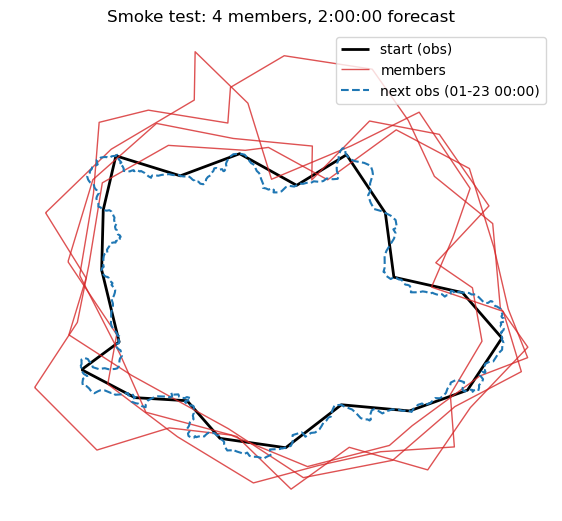

Members should start at the black perimeter and grow away from it. Next obs is only for reference (the smoke test may stop well before it).


In [10]:
if SMOKE_OK:
    # 5. look at it: start perimeter, each member's forecast, and the next observation
    def state_to_polygon(vec):
        v = np.asarray(vec).ravel()
        return Polygon(np.c_[v[0::2], v[1::2]])

    fig, ax = plt.subplots(figsize=(7, 7))
    gpd.GeoSeries([state_to_polygon(state_vec)], crs=5070).boundary.plot(ax=ax, color='k', lw=2, label='start (obs)')
    for j in range(SMOKE_N):
        if ens.valid_mask[j]:
            gpd.GeoSeries([state_to_polygon(ens.forecast[:, j])], crs=5070).boundary.plot(
                ax=ax, color='#d62728', lw=1, alpha=0.8, label='members' if j == 0 else None)
    nxt = read_perimeter(second)
    gpd.GeoSeries([nxt], crs=5070).boundary.plot(ax=ax, color='#1f77b4', lw=1.5, ls='--',
                                                 label=f'next obs ({second.obs_time:%m-%d %H:%M})')
    ax.set_title(f'Smoke test: {SMOKE_N} members, {dt} forecast'); ax.legend(); ax.set_axis_off()
    plt.show()
    print('Members should start at the black perimeter and grow away from it. Next obs is only for reference '
          '(the smoke test may stop well before it).')